### Linear Least Squares For a Polynomial Problem

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
u_i = np.random.uniform(-1, 1, 200)
u = np.sort(u_i)
v_i = u**2 + 0.2*np.random.normal(0,1, 200)


In [4]:
A = np.column_stack((u**2, u, np.ones(200)))
b = v_i.reshape(200)

In [5]:
xls = np.linalg.inv(A.T @ A) @ A.T @ b
l2error = np.linalg.norm(v_i - A @ xls, 2)
l2error


np.float64(3.0333337358195642)

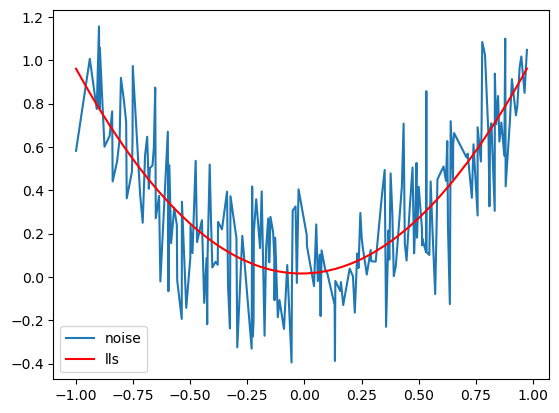

In [6]:
a = xls[0]
b = xls[1]
c = xls[2]
plt.plot(u, v_i,label = 'noise')
plt.plot(u, a*u**2 + b*u + c, color = 'red', label = 'lls')
plt.legend()

### Regularised Least Squares

In [7]:
L = np.zeros((199,200))
for i in range(199):
    L[i,i] = 1
    L[i,i+1] = -1
# Regularisation parameter 

In [8]:
I = np.identity(200)
lda = 100
b = v_i.reshape(200)
xrls = np.linalg.inv(I + lda * L.T @ L) @ b

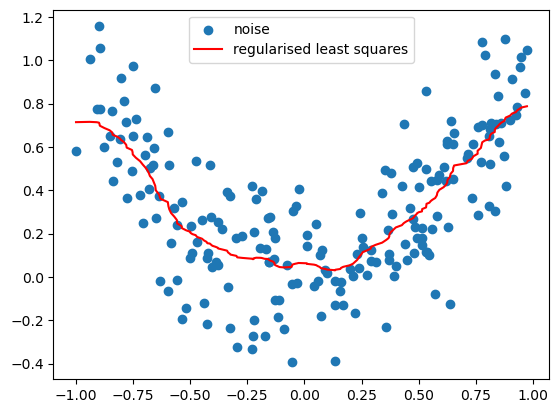

In [9]:
plt.scatter(u, v_i, label = 'noise')
plt.plot(u, xrls, color = 'red', label = 'regularised least squares')
plt.legend()

### Overfitting

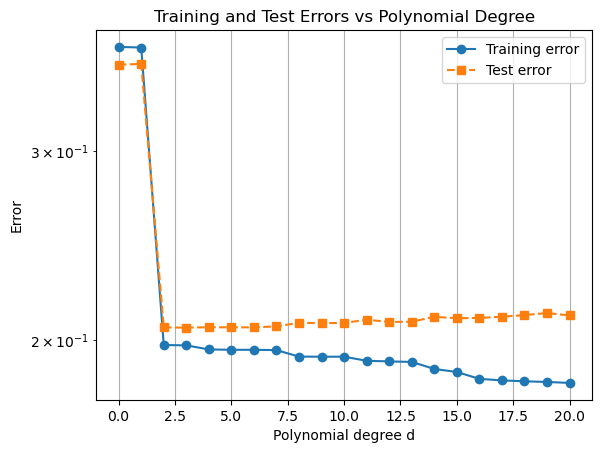

In [10]:
Ns = 200

u = 2 * np.random.rand(Ns) - 1
v = u**2 + 0.2 * np.random.normal(0, 1, Ns)

ut = 2 * np.random.rand(Ns) - 1
vt = ut**2 + 0.2 * np.random.normal(0, 1, Ns)

# Initialise error arrays
etrain = []
etest = []

# Fit polynomial models of degree 0 to 20
for d in range(21):

    # Design matrices: columns are 1, u, u^2, ..., u^d
    A = np.column_stack([u**k for k in range(d + 1)])
    At = np.column_stack([ut**k for k in range(d + 1)])

    # Least squares coefficients
    x = np.linalg.lstsq(A, v, rcond=None)[0]

    # Training and test errors
    etrain.append(np.linalg.norm(A @ x - v) / np.sqrt(Ns))
    etest.append(np.linalg.norm(At @ x - vt) / np.sqrt(Ns))

# Plot errors against polynomial degree
plt.semilogy(range(21), etrain, 'o-', label='Training error')
plt.semilogy(range(21), etest, 's--', label='Test error')

plt.xlabel('Polynomial degree d')
plt.ylabel('Error')
plt.title('Training and Test Errors vs Polynomial Degree')
plt.legend()
plt.grid(True)
plt.show()

In [11]:
v0 = u**2  # noiseless data

err = []
kap = []

for d in range(2, 21):

    # Design matrix with columns 1, u, u^2, ..., u^d
    A = np.column_stack([u**k for k in range(d + 1)])

    # True coefficient vector: coefficient of u^2 is 1
    xtrue = np.zeros(d + 1)
    xtrue[2] = 1

    # Solve using normal equations
    xne = np.linalg.solve(A.T @ A, A.T @ v0)

    # Solve using least squares
    xqr = np.linalg.lstsq(A, v0, rcond=None)[0]

    # Compare coefficient errors
    err.append([
        np.linalg.norm(xne - xtrue),
        np.linalg.norm(xqr - xtrue)
    ])

    # Calculate condition numbers
    kap.append([
        np.linalg.cond(A),
        np.linalg.cond(A.T @ A)
    ])

err = np.array(err)
kap = np.array(kap)

In [12]:
err, kap

(array([[5.84181038e-18, 2.78085454e-16],
        [6.72439932e-17, 2.40325188e-16],
        [6.07688280e-16, 1.25078314e-15],
        [6.93457846e-16, 9.42698089e-16],
        [1.09519208e-14, 1.86355199e-15],
        [1.09829772e-14, 7.35834326e-16],
        [3.11791862e-13, 1.26819944e-15],
        [4.09431919e-13, 1.37792283e-15],
        [1.28613131e-11, 1.53811105e-15],
        [2.41555272e-11, 1.63563441e-15],
        [1.10880360e-09, 1.38866316e-14],
        [1.13514133e-09, 8.06190968e-14],
        [3.84934728e-08, 8.31217813e-14],
        [4.02482372e-08, 4.67977717e-14],
        [8.38745494e-07, 3.97704762e-13],
        [9.82127337e-07, 1.06658749e-12],
        [1.36925858e-05, 3.88080657e-12],
        [1.92937112e-05, 7.71018488e-12],
        [3.55990463e-05, 1.94408995e-11]]),
 array([[3.71846362e+00, 1.38269717e+01],
        [8.51530462e+00, 7.25104127e+01],
        [1.97588264e+01, 3.90411221e+02],
        [4.44267793e+01, 1.97373872e+03],
        [1.03507042e+02, 1.07137

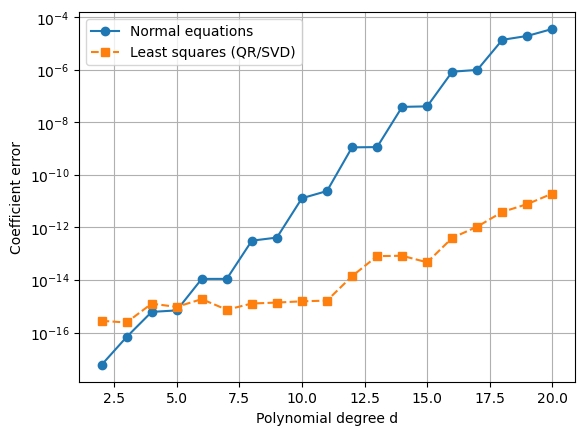

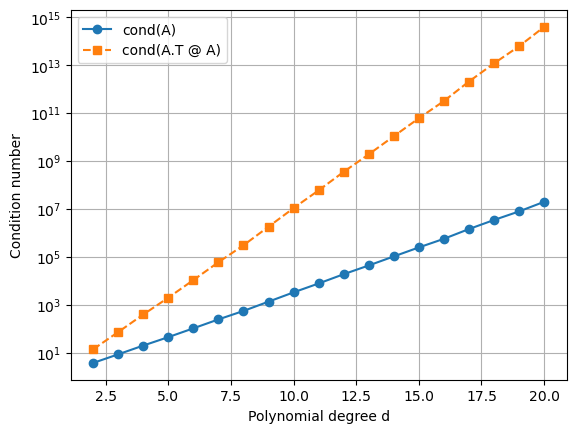

In [13]:
degrees = range(2, 21)

plt.figure()
plt.semilogy(degrees, err[:, 0], 'o-', label='Normal equations')
plt.semilogy(degrees, err[:, 1], 's--', label='Least squares (QR/SVD)')
plt.xlabel('Polynomial degree d')
plt.ylabel('Coefficient error')
plt.legend()
plt.grid(True)
plt.show()

plt.figure()
plt.semilogy(degrees, kap[:, 0], 'o-', label='cond(A)')
plt.semilogy(degrees, kap[:, 1], 's--', label='cond(A.T @ A)')
plt.xlabel('Polynomial degree d')
plt.ylabel('Condition number')
plt.legend()
plt.grid(True)
plt.show()

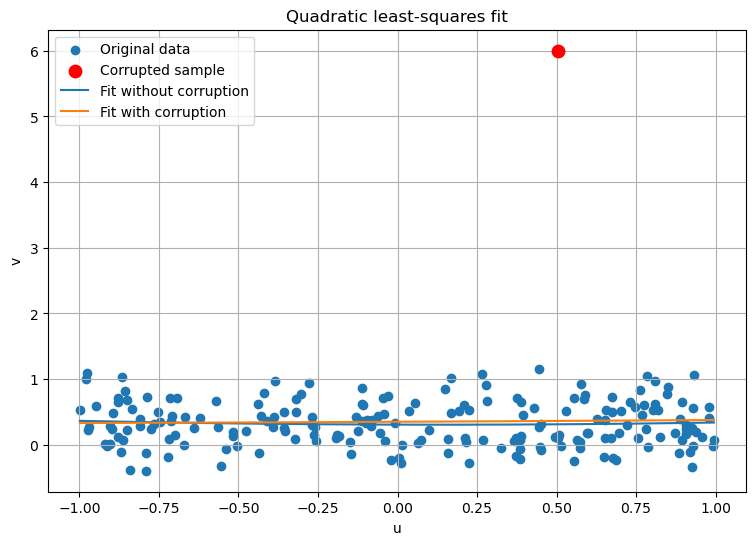

Clean coefficients: [ 0.04536728 -0.0127675   0.30639248]
Corrupted coefficients: [0.00404014 0.02304643 0.34981786]


In [14]:
# Assume u and v are your original data arrays, each of length 30
u = np.asarray(u).flatten()
v = np.asarray(b).flatten()

# 1. Randomly reorder the data
idx = np.random.permutation(len(u))
u0 = u[idx]
vc = v[idx]

# 2. Copy the outputs and corrupt the sample where u is closest to 0.5
vo = vc.copy()
i0 = np.argmin(np.abs(u0 - 0.5))
vo[i0] = 6

# 3. Construct the quadratic design matrix
A = np.column_stack((u0**2, u0, np.ones(len(u0))))

# 4. Fit the model using least squares
x_clean = np.linalg.lstsq(A, vc, rcond=None)[0]
x_corr = np.linalg.lstsq(A, vo, rcond=None)[0]

# 5. Generate smooth fitted curves
u_plot = np.linspace(u0.min(), u0.max(), 300)

y_clean = (
    x_clean[0] * u_plot**2
    + x_clean[1] * u_plot
    + x_clean[2]
)

y_corr = (
    x_corr[0] * u_plot**2
    + x_corr[1] * u_plot
    + x_corr[2]
)

# 6. Plot the original data, corrupted data and both fits
plt.figure(figsize=(9, 6))

plt.scatter(u0, vc, label="Original data")
plt.scatter(u0[i0], vo[i0], color="red", s=80,
            label="Corrupted sample", zorder=3)

plt.plot(u_plot, y_clean, label="Fit without corruption")
plt.plot(u_plot, y_corr, label="Fit with corruption")

plt.xlabel("u")
plt.ylabel("v")
plt.title("Quadratic least-squares fit")
plt.legend()
plt.grid(True)
plt.show()

print("Clean coefficients:", x_clean)
print("Corrupted coefficients:", x_corr)


The corrupted observation pulls the regression line towards that observation and alters the coefficients.